# Zoo : arbre de décision et jeu de la devinette intelligent

1. **Arbre de décision** (entropie) avec les vrais noms de classes + validation croisée.
2. **Jeu de la devinette intelligent** : à chaque tour, le programme pose la question qui apporte le **plus d'information** (gain d'information).
3. **Jeu de données enrichi** (`zoo_etendu.csv`) : 16 nouvelles caractéristiques (régime alimentaire, vie en groupe, taille, milieu de vie...) pour pouvoir distinguer des animaux que le fichier d'origine ne séparait pas (lion / léopard / loup...).

Fichiers nécessaires dans le même dossier : `zoo_etendu.csv` (contient toutes les colonnes de `zoo.csv` + les nouvelles).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score, StratifiedKFold

zoo_data = pd.read_csv('zoo_etendu.csv')

HORS_FEATURES = ('animal_name', 'class_type')
TOUTES = [c for c in zoo_data.columns if c not in HORS_FEATURES]
FEATURES_ORIGINALES = TOUTES[:TOUTES.index('catsize') + 1]   # colonnes de zoo.csv
FEATURES_NOUVELLES = TOUTES[TOUTES.index('catsize') + 1:]    # colonnes ajoutées

print(zoo_data.shape, '|', len(FEATURES_ORIGINALES), 'caractéristiques d\'origine +', len(FEATURES_NOUVELLES), 'nouvelles')
zoo_data.head()

(101, 34) | 16 caractéristiques d'origine + 16 nouvelles


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,...,desert,nocturnal,arboreal,burrows,freshwater,horns,long_neck,ruminant,songbird,class_type
0,aardvark,1,0,0,1,0,0,1,1,1,...,0,1,0,1,0,0,0,0,0,1
1,antelope,1,0,0,1,0,0,0,1,1,...,0,0,0,0,0,1,0,1,0,1
2,bass,0,0,1,0,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,1
4,boar,1,0,0,1,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,1


## Les nouvelles caractéristiques

| Colonne | Signification (1 = oui) |
|---|---|
| `herbivore` | mange surtout des végétaux (herbe, feuilles, graines, fruits, nectar) |
| `omnivore` | mange végétaux **et** animaux |
| `social` | vit en groupe (troupeau, banc, meute, colonie, volée) |
| `heavy` | pèse plus d'un humain adulte (> 70 kg) |
| `small` | pèse moins de 2 kg |
| `tropical` | vit surtout dans les régions chaudes (tropiques, savane) |
| `cold` | vit surtout dans les régions froides (pôles, toundra, mers froides) |
| `desert` | vit dans les déserts / régions arides |
| `nocturnal` | surtout actif la nuit |
| `arboreal` | vit ou se perche dans les arbres / buissons |
| `burrows` | vit sous terre ou enfoui (terrier, sable, vase) |
| `freshwater` | vit en eau douce |
| `horns` | a des cornes ou des bois |
| `long_neck` | a un cou très long |
| `ruminant` | rumine (remâche son herbe) |
| `songbird` | petit oiseau chanteur (passereau) |

Ces valeurs sont des **approximations de bon sens** (un « antelope » ou un « deer » générique n'existe pas vraiment) : vous pouvez les corriger directement dans `zoo_etendu.csv`.

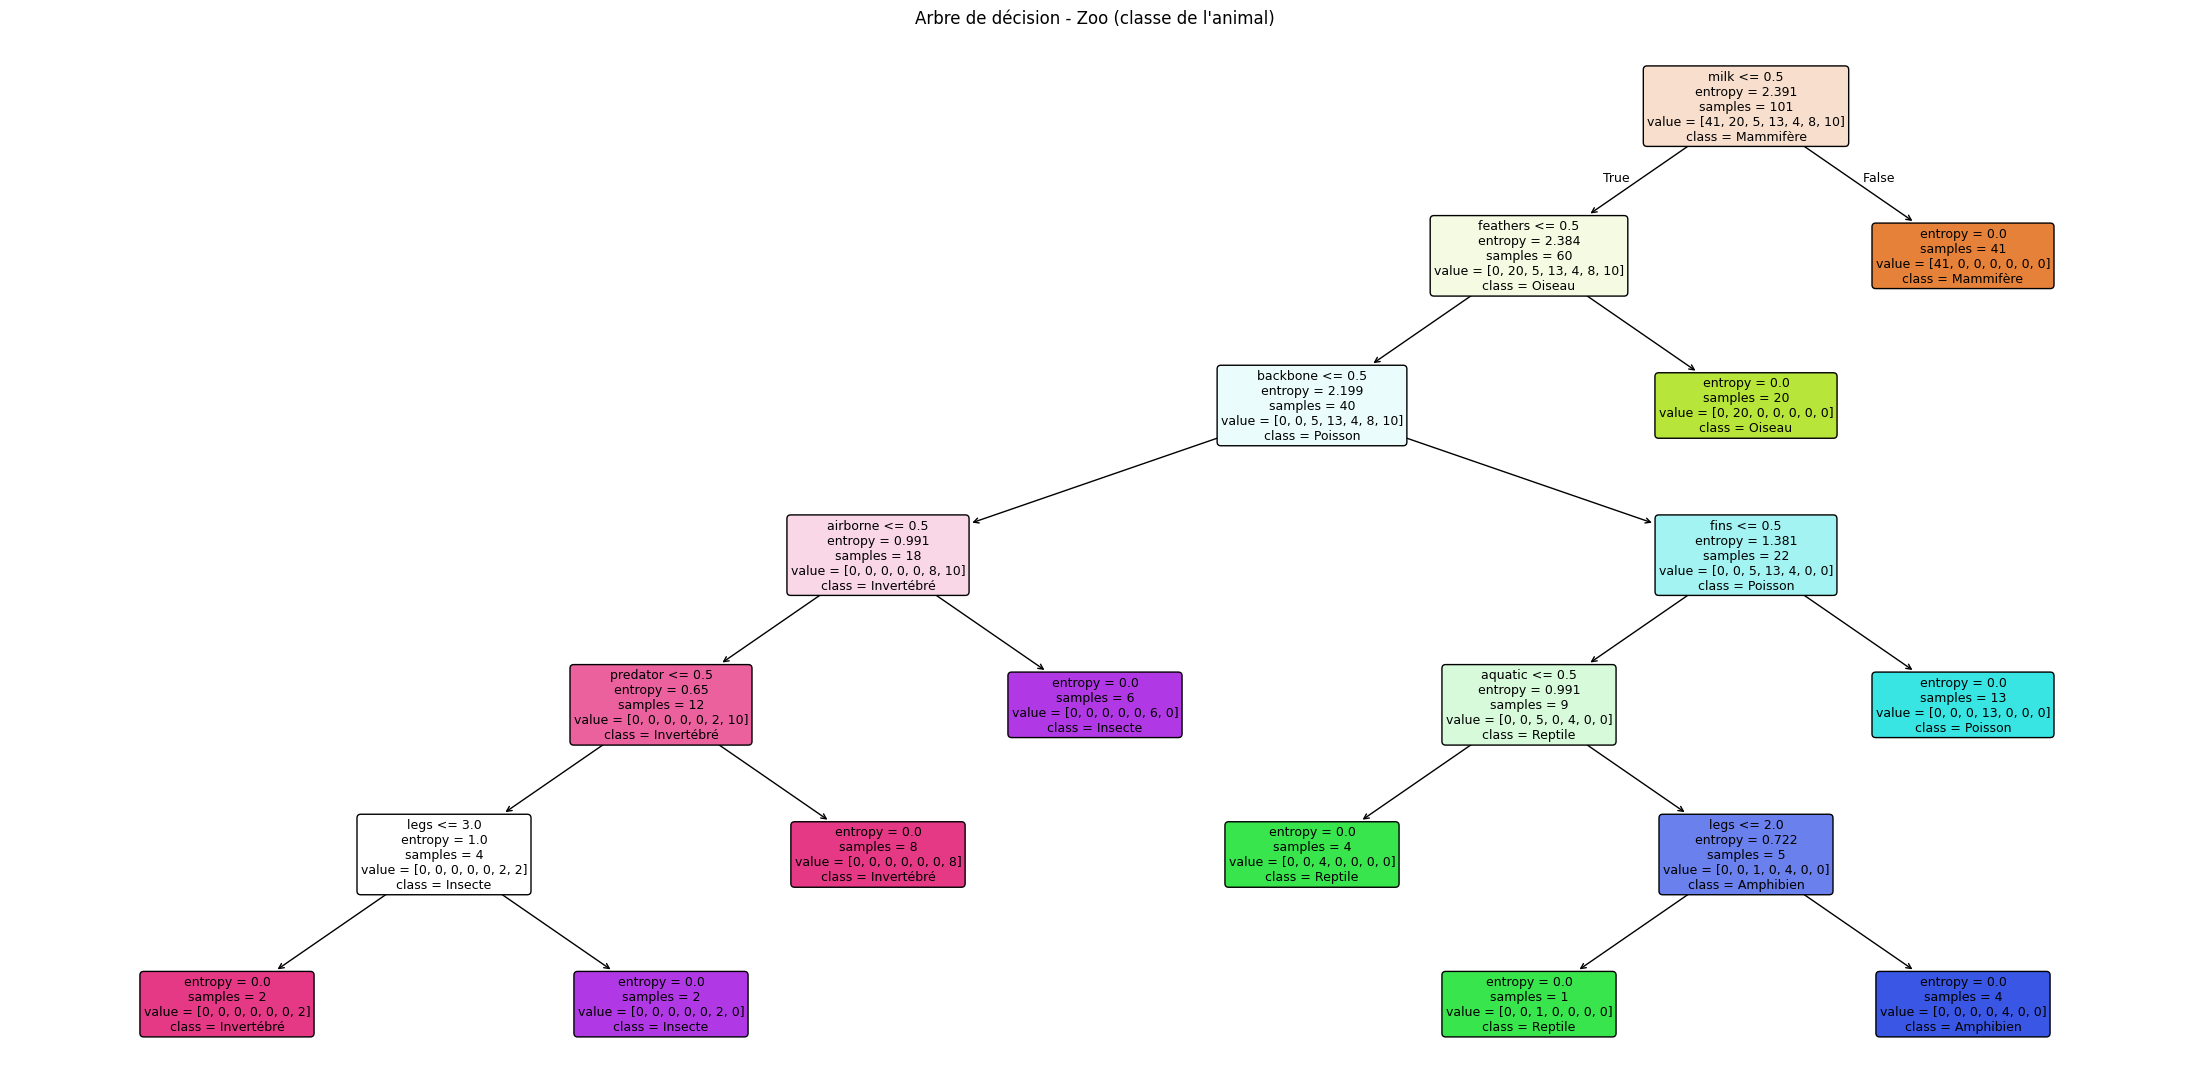

Précision en validation croisée : 96.1% (+/- 2.7%)


In [2]:
CLASSES_FR = {1: 'Mammifère', 2: 'Oiseau', 3: 'Reptile', 4: 'Poisson',
              5: 'Amphibien', 6: 'Insecte', 7: 'Invertébré'}

X = zoo_data[FEATURES_ORIGINALES]
y = zoo_data['class_type']

clf = DecisionTreeClassifier(criterion='entropy', random_state=0)
clf.fit(X, y)

# clf.classes_ est trié : c'est l'ordre attendu par plot_tree
noms_classes = [CLASSES_FR[c] for c in clf.classes_]

plt.figure(figsize=(22, 11))
plot_tree(clf, feature_names=X.columns.tolist(), class_names=noms_classes,
          filled=True, rounded=True, fontsize=9)
plt.title("Arbre de décision - Zoo (classe de l'animal)")
plt.tight_layout()
plt.show()

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)
scores = cross_val_score(DecisionTreeClassifier(criterion='entropy', random_state=0), X, y, cv=cv)
print(f"Précision en validation croisée : {scores.mean():.1%} (+/- {scores.std():.1%})")

In [3]:
QUESTIONS = {
    # --- caractéristiques d'origine ---
    'hair':     "A-t-il des poils ?",
    'feathers': "A-t-il des plumes ?",
    'eggs':     "Pond-il des œufs ?",
    'milk':     "Produit-il du lait (allaite-t-il ses petits) ?",
    'airborne': "Peut-il voler ?",
    'aquatic':  "Vit-il dans l'eau ?",
    'predator': "Est-ce un prédateur ?",
    'toothed':  "A-t-il des dents ?",
    'backbone': "A-t-il une colonne vertébrale ?",
    'breathes': "Respire-t-il de l'air (poumons) ?",
    'venomous': "Est-il venimeux ?",
    'fins':     "A-t-il des nageoires ?",
    'legs':     "Combien de pattes a-t-il ?",
    'tail':     "A-t-il une queue ?",
    'domestic': "Est-il domestique ?",
    'catsize':  "Est-il de la taille d'un chat ou plus grand ?",
    # --- nouvelles caractéristiques ---
    'herbivore':  "Mange-t-il surtout des végétaux (herbe, feuilles, graines, fruits, nectar) ?",
    'omnivore':   "Mange-t-il à la fois des végétaux et des animaux (omnivore) ?",
    'social':     "Vit-il en groupe (troupeau, banc, meute, colonie, volée) ?",
    'heavy':      "Pèse-t-il plus qu'un humain adulte (plus de 70 kg) ?",
    'small':      "Pèse-t-il moins de 2 kg ?",
    'tropical':   "Vit-il surtout dans les régions chaudes (tropiques, savane) ?",
    'cold':       "Vit-il surtout dans les régions froides (pôles, toundra, mers froides) ?",
    'desert':     "Vit-il dans les déserts ou les régions arides ?",
    'nocturnal':  "Est-il surtout actif la nuit ?",
    'arboreal':   "Vit-il ou se perche-t-il dans les arbres ou les buissons ?",
    'burrows':    "Vit-il sous terre ou enfoui dans le sol / le sable / la vase (terrier) ?",
    'freshwater': "Vit-il en eau douce (rivières, lacs, étangs) ?",
    'horns':      "A-t-il des cornes ou des bois ?",
    'long_neck':  "A-t-il un cou très long ?",
    'ruminant':   "Rumine-t-il (remâche-t-il son herbe, comme une vache) ?",
    'songbird':   "Est-ce un petit oiseau chanteur (passereau) ?",
}

# Les nouvelles caractéristiques sont plus subjectives que les anciennes : on les pénalise un peu
# pour préférer, à gain d'information presque égal, une question dont la réponse est sûre.
CONFIANCE_NOUVELLES = 0.9


class Devinette:
    # Jeu de la devinette basé sur le gain d'information.

    def __init__(self, data, features):
        self.data = data
        self.features = list(features)
        # Animaux aux caractéristiques identiques = un seul « profil » (impossible de les distinguer)
        self.profils = (data.groupby(self.features, as_index=False)
                        .agg(animaux=('animal_name', lambda s: sorted(set(s))),
                             poids=('animal_name', 'size'),
                             class_type=('class_type', 'first')))

    @staticmethod
    def entropie(poids):
        p = np.asarray(poids, dtype=float)
        p = p / p.sum()
        return float(-(p * np.log2(p)).sum())

    def gain(self, cand, f):
        # entropie avant - entropie moyenne attendue après la réponse
        apres = sum(g['poids'].sum() / cand['poids'].sum() * self.entropie(g['poids'])
                    for _, g in cand.groupby(f))
        g = self.entropie(cand['poids']) - apres
        return g * (CONFIANCE_NOUVELLES if f in FEATURES_NOUVELLES else 1.0)

    def meilleure_question(self, cand, deja):
        dispo = [f for f in self.features if f not in deja and cand[f].nunique() > 1]
        return max(dispo, key=lambda f: self.gain(cand, f)) if dispo else None

    def plus_proches(self, reponses):
        # Profils contredisant le moins de réponses (utile si l'utilisateur s'est trompé)
        erreurs = sum((self.profils[f] != v).astype(int) for f, v in reponses.items())
        return self.profils[erreurs == erreurs.min()], int(erreurs.min())

    @staticmethod
    def lire_reponse(f, valeurs):
        # Retourne la valeur choisie, 'nsp' (je ne sais pas) ou 'q' (quitter)
        while True:
            if f == 'legs':
                rep = input(f"   Valeurs possibles {sorted(valeurs)} (ou 'nsp' / 'q') -> ").strip().lower()
            else:
                rep = input("   (oui / non / nsp = je ne sais pas / q = quitter) -> ").strip().lower()
            if rep in ('q', 'quitter'):
                return 'q'
            if rep in ('nsp', '?', 'je ne sais pas', 'jsp'):
                return 'nsp'
            if f == 'legs':
                if rep.isdigit() and int(rep) in valeurs:
                    return int(rep)
            elif rep in ('oui', 'o', 'yes', 'y', '1'):
                return 1
            elif rep in ('non', 'n', 'no', '0'):
                return 0
            print("   Réponse non reconnue, essayez encore.")

    def jouer(self, secret=None, verbose=True):
        # secret : nom d'un animal -> mode simulation (réponses automatiques), sinon mode interactif.
        log = print if verbose else (lambda *a, **k: None)
        if secret is not None:
            ligne = self.data[self.data.animal_name == secret].iloc[0]

        log("\nBienvenue dans le jeu de la devinette !")
        if secret is None:
            log("Pensez à un animal, je vais essayer de le deviner. Répondez par oui / non (ou nsp si vous ne savez pas).")

        cand = self.profils.copy()
        deja, reponses, n_questions = set(), {}, 0

        # on s'arrête quand il ne reste qu'un seul nom d'animal possible
        while len({a for l in cand['animaux'] for a in l}) > 1:
            f = self.meilleure_question(cand, deja)
            if f is None:          # plus aucune question utile (trop de « nsp »)
                break
            deja.add(f)
            n_questions += 1
            log(f"\nQ{n_questions}. {QUESTIONS[f]}")

            if secret is not None:
                rep = int(ligne[f])
                log(f"   -> {rep}")
            else:
                rep = self.lire_reponse(f, set(cand[f]))
                if rep == 'q':
                    log("Partie interrompue.")
                    return None
                if rep == 'nsp':
                    n_questions -= 1
                    continue

            reponses[f] = rep
            suivant = cand[cand[f] == rep]
            if suivant.empty:
                log("\nVos réponses sont contradictoires avec tous les animaux connus.")
                proches, nb = self.plus_proches(reponses)
                noms = sorted({a for l in proches['animaux'] for a in l})
                log(f"Les plus proches (avec {nb} désaccord(s)) : {noms}")
                return {'questions': n_questions, 'animaux': noms, 'exact': False}
            cand = suivant
            log(f"   (il reste {int(cand['poids'].sum())} animaux possibles)")

        animaux = sorted({a for l in cand['animaux'] for a in l})
        classes = sorted({CLASSES_FR[c] for c in cand['class_type']})

        if len(animaux) == 1:
            log(f"\nJe pense que vous avez choisi : {animaux[0]}  ({classes[0]})")
        elif len(cand) == 1:
            log(f"\nJe pense que c'est l'un de ces animaux : {animaux}")
            log("Ils ont exactement les mêmes caractéristiques dans les données, je ne peux pas les départager.")
            log(f"Classe : {', '.join(classes)}")
        else:
            log(f"\nJe n'ai pas pu conclure. Candidats possibles : {animaux}")
            log(f"Classe(s) probable(s) : {', '.join(classes)}")

        return {'questions': n_questions, 'animaux': animaux, 'exact': True}


jeu_etendu = Devinette(zoo_data, TOUTES)                 # avec les nouvelles caractéristiques
jeu_origine = Devinette(zoo_data, FEATURES_ORIGINALES)   # données d'origine seulement

for nom, j in [("données d'origine", jeu_origine), ("données étendues", jeu_etendu)]:
    print(f"{nom} : {len(zoo_data)} animaux -> {len(j.profils)} profils distinguables")
    reste = [l for l in j.profils['animaux'] if len(l) > 1]
    print(f"   groupes d'animaux impossibles à séparer : {len(reste)}")

données d'origine : 101 animaux -> 59 profils distinguables
   groupes d'animaux impossibles à séparer : 19
données étendues : 101 animaux -> 101 profils distinguables
   groupes d'animaux impossibles à séparer : 0


## Test automatique : trois stratégies comparées

Chaque animal du fichier joue le rôle de l'« animal secret » et on mesure le nombre de questions et le taux de réussite.

In [4]:
def ancienne_strategie(secret):
    # Version d'origine : colonnes dans l'ordre, binaires uniquement (legs ignoré), données d'origine
    ligne = zoo_data[zoo_data.animal_name == secret].iloc[0]
    df, n = zoo_data.copy(), 0
    for col in FEATURES_ORIGINALES:
        if len(df) <= 1:
            break
        if df[col].nunique() == 2:
            df = df[df[col] == ligne[col]]
            n += 1
    return {'questions': n, 'animaux': sorted(set(df.animal_name))}


def evaluer(fonction):
    lignes = []
    for nom in sorted(zoo_data.animal_name.unique()):
        r = fonction(nom)
        lignes.append({'questions': r['questions'], 'taille_groupe': len(r['animaux']),
                       'correct': nom in r['animaux']})
    d = pd.DataFrame(lignes)
    return {'Questions (moyenne)': round(d.questions.mean(), 1),
            'Questions (max)': int(d.questions.max()),
            'Animal exact trouvé': f"{(d.taille_groupe == 1).mean():.0%}",
            'Bonne réponse incluse': f"{d.correct.mean():.0%}"}


tableau = pd.DataFrame({
    "1. Ancienne stratégie (données d'origine)": evaluer(ancienne_strategie),
    "2. Gain d'information (données d'origine)": evaluer(lambda n: jeu_origine.jouer(secret=n, verbose=False)),
    "3. Gain d'information (données étendues)":  evaluer(lambda n: jeu_etendu.jouer(secret=n, verbose=False)),
})
tableau

,1. Ancienne stratégie (données d'origine),2. Gain d'information (données d'origine),3. Gain d'information (données étendues)
Questions (moyenne),7.5,4.9,5.8
Questions (max),10,7,8
Animal exact trouvé,37%,39%,100%
Bonne réponse incluse,100%,100%,100%


## Jouer !

In [ ]:
jeu_etendu.jouer()